# CNN for Cat and Dog Classification
**ECE 5831 · Part 2**


## 1. Environment and settings

Select the Python environment used for the course in Jupyter or VS Code. If a
package is missing, run the installation command below once, restart the kernel,
and choose **Run All**. A CPU is sufficient; a compatible GPU can reduce training time.


In [1]:
# Uncomment only if packages are missing, then restart the kernel.
# %pip install tensorflow numpy matplotlib pillow


In [2]:
from pathlib import Path
from collections import Counter
import hashlib
import io
import re
import time
import os
import json
import sys

os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '4')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
IMAGE_SIZE = (96, 96)
BATCH_SIZE = 32
EPOCHS = 10
CLASS_NAMES = ['cat', 'dog']

# Set this to the extracted Canvas dataset folder, not to the ZIP file.
# Windows example: Path(r'C:\Users\your_name\Downloads\dataset')
DATA_DIR = Path('cat_dog_dataset')
RUN_DIR = Path('cnn_run')
RUN_DIR.mkdir(exist_ok=True)

keras.utils.set_random_seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False})
DATA_READY = False
TRAINING_COMPLETED = False
EVALUATION_COMPLETED = False
PREDICTIONS_COMPLETED = False
history = None

print('TensorFlow:', tf.__version__)
print('Python:', sys.version.split()[0])
print('Keras:', getattr(keras, '__version__', 'bundled with TensorFlow'))
print('Dataset folder:', DATA_DIR.resolve())
print('Class mapping:', dict(enumerate(CLASS_NAMES)))
print('Epochs:', EPOCHS)


TensorFlow: 2.20.0
Python: 3.12.14
Keras: 3.15.1
Dataset folder: /workspace/scratch/e3308c41fee7/deliverables/cat_dog_dataset
Class mapping: {0: 'cat', 1: 'dog'}
Epochs: 10


## 2. Find and check the Canvas images

Supported layouts include `cats/` and `dogs/` folders, or those class folders
inside `train/`, `validation/`, and `test/`. Names such as `training_set`,
`test_set`, and `testing_set` are recognized, including repeated wrapper folders
such as `dataset/training_set/training_set/cats`. Flat files named `cat.1.jpg`
and `dog.1.jpg` are also recognized.

Existing validation and test sets are preserved. If only training and test sets
exist, 20% of each training class is reserved for validation. If no splits exist,
the notebook creates approximately 70% training, 15% validation, and 15% testing
for each class with a fixed random seed.

Unreadable files are reported and excluded. Identical file copies are counted
once. When a file appears in multiple supplied splits, the test copy takes
priority, followed by validation and then training. This removes training/test
overlap without moving a test image into training. Contradictory labels for the
same file stop preparation. Source images are preserved; exclusions affect only
the records used by the model.


In [3]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}
LABEL_ALIASES = {'cat': 0, 'cats': 0, 'dog': 1, 'dogs': 1}
SPLIT_ALIASES = {
    'train': 'train', 'training': 'train', 'train_set': 'train',
    'training_set': 'train',
    'val': 'validation', 'valid': 'validation', 'validation': 'validation',
    'val_set': 'validation', 'valid_set': 'validation',
    'validation_set': 'validation',
    'test': 'test', 'testing': 'test', 'test_set': 'test',
    'testing_set': 'test',
}


def discover_images(root):
    """Return labeled, decodable records without changing source files."""
    candidates, bad_files, unlabeled = [], [], []
    for path in sorted(root.rglob('*')):
        relative = path.relative_to(root)
        if (not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS
                or any(part.startswith('.') or part == '__MACOSX'
                       for part in relative.parts)):
            continue
        folders = [part.lower().replace('-', '_') for part in relative.parts[:-1]]
        labels = {LABEL_ALIASES[part] for part in folders if part in LABEL_ALIASES}
        if not labels:
            match = re.match(r'^(cat|dog)[._ -]', path.name.lower())
            if match:
                labels = {LABEL_ALIASES[match.group(1)]}
        if len(labels) > 1:
            raise ValueError(f'Ambiguous cat/dog folder labels: {relative}')
        if not labels:
            unlabeled.append(str(relative))
            continue
        splits = {SPLIT_ALIASES[part] for part in folders if part in SPLIT_ALIASES}
        if len(splits) > 1:
            raise ValueError(f'Ambiguous train/validation/test folders: {relative}')
        label = labels.pop()
        split = splits.pop() if splits else 'unsplit'
        try:
            raw = path.read_bytes()
            with Image.open(io.BytesIO(raw)) as image:
                image.verify()
            # Check the same decoder that will be used in the training pipeline.
            decoded = tf.io.decode_image(raw, channels=3, expand_animations=False)
            if int(tf.size(decoded)) == 0:
                raise ValueError('Empty image')
        except Exception as error:
            bad_files.append((str(relative), type(error).__name__))
            continue
        digest = hashlib.sha256(raw).hexdigest()
        record = {'path': str(path.resolve()), 'label': label,
                  'source_split': split, 'sha256': digest}
        candidates.append(record)
    # Preserve held-out examples when exact copies also occur in training.
    priority = {'test': 0, 'validation': 1, 'train': 2, 'unsplit': 3}
    records, duplicates, seen_hashes = [], [], {}
    for record in sorted(candidates,
                         key=lambda r: (priority[r['source_split']], r['path'])):
        previous = seen_hashes.get(record['sha256'])
        if previous is not None:
            if previous['label'] != record['label']:
                raise ValueError('Identical image has conflicting labels: ' + record['path'])
            duplicates.append({'excluded': record, 'kept': previous})
        else:
            records.append(record)
            seen_hashes[record['sha256']] = record
    return records, bad_files, unlabeled, duplicates


if DATA_DIR.is_dir():
    records, bad_files, unlabeled, duplicates = discover_images(DATA_DIR)
    if not records:
        raise ValueError('No labeled images found. Check DATA_DIR and the layout above.')
    print('Usable labeled images:', len(records))
    print('Unreadable files excluded:', len(bad_files))
    print('Unlabeled images excluded:', len(unlabeled))
    print('Exact duplicate copies excluded:', len(duplicates))
    cross_split_duplicates = sum(d['excluded']['source_split'] != d['kept']['source_split']
                                for d in duplicates)
    print('Duplicates across supplied splits:', cross_split_duplicates)
    for duplicate in duplicates:
        excluded = Path(duplicate['excluded']['path']).relative_to(DATA_DIR.resolve())
        kept = Path(duplicate['kept']['path']).relative_to(DATA_DIR.resolve())
        print(f'  Duplicate excluded: {excluded}; retained: {kept}')
    for name, reason in bad_files[:5]:
        print('  Unreadable:', name, '(' + reason + ')')
    for name in unlabeled[:5]:
        print('  No label:', name)
    print('Source split counts:', dict(Counter(r['source_split'] for r in records)))
    DATA_READY = True
else:
    print('PENDING — Canvas cat-and-dog dataset is not available.')
    print('Extract the Canvas dataset, update DATA_DIR, and run all cells again.')


Usable labeled images: 24984
Unreadable files excluded: 0
Unlabeled images excluded: 0
Exact duplicate copies excluded: 5
Duplicates across supplied splits: 2
  Duplicate excluded: data_from_kaggle/test/cat.3345.jpg; retained: data_from_kaggle/test/cat.10360.jpg
  Duplicate excluded: data_from_kaggle/train/cat.2339.jpg; retained: data_from_kaggle/train/cat.12408.jpg
  Duplicate excluded: data_from_kaggle/train/cat.6204.jpg; retained: data_from_kaggle/train/cat.6143.jpg
  Duplicate excluded: data_from_kaggle/train/dog.2877.jpg; retained: data_from_kaggle/test/dog.10401.jpg
  Duplicate excluded: data_from_kaggle/train/dog.3082.jpg; retained: data_from_kaggle/test/dog.2027.jpg
Source split counts: {'test': 4999, 'train': 19985}


In [4]:
def reserve_stratified(items, fraction, seed):
    """Hold out the requested fraction separately within each class."""
    rng = np.random.default_rng(seed)
    remaining, held_out = [], []
    for label in (0, 1):
        group = [item for item in items if item['label'] == label]
        if len(group) < 2:
            raise ValueError(f'Not enough {CLASS_NAMES[label]} images for a split.')
        order = rng.permutation(len(group))
        n_holdout = min(len(group) - 1, max(1, round(len(group) * fraction)))
        held_out.extend(group[i] for i in order[:n_holdout])
        remaining.extend(group[i] for i in order[n_holdout:])
    return remaining, held_out


if DATA_READY:
    groups = {name: [r for r in records if r['source_split'] == name]
              for name in ('train', 'validation', 'test', 'unsplit')}
    if groups['unsplit'] and any(groups[name] for name in ('train', 'validation', 'test')):
        raise ValueError('Mixed unsplit/split images. Set DATA_DIR to one dataset root.')
    train_records = groups['train'] or groups['unsplit']
    val_records, test_records = groups['validation'], groups['test']
    if not train_records:
        raise ValueError('No training images found. DATA_DIR must include training data.')

    if not val_records and not test_records:
        train_records, test_records = reserve_stratified(train_records, 0.15, SEED)
        train_records, val_records = reserve_stratified(train_records, 0.15 / 0.85, SEED + 1)
        split_policy = 'Created approximately 70% train / 15% validation / 15% test.'
    elif not val_records:
        train_records, val_records = reserve_stratified(train_records, 0.20, SEED)
        split_policy = 'Preserved the test set; held out 20% of training for validation.'
    elif not test_records:
        train_records, test_records = reserve_stratified(train_records, 0.20, SEED)
        split_policy = 'Preserved validation; held out 20% of training for a labeled test set.'
    else:
        split_policy = 'Preserved all three supplied splits.'

    split_records = {'Training': train_records, 'Validation': val_records,
                     'Test': test_records}
    hashes = []
    print(split_policy)
    print(f"{'Split':<14}{'Cats':>8}{'Dogs':>8}{'Total':>9}")
    for name, items in split_records.items():
        counts = Counter(item['label'] for item in items)
        assert counts[0] > 0 and counts[1] > 0, f'{name} needs both classes.'
        hashes.append({item['sha256'] for item in items})
        print(f'{name:<14}{counts[0]:>8}{counts[1]:>8}{len(items):>9}')
    assert not (hashes[0] & hashes[1] or hashes[0] & hashes[2] or hashes[1] & hashes[2])
    assert sum(map(len, split_records.values())) == len(records)
    print('Checks passed: both classes in every split; no identical files across splits.')
else:
    print('PENDING — train/validation/test preparation needs the Canvas dataset.')


Preserved the test set; held out 20% of training for validation.
Split             Cats    Dogs    Total
Training          7998    7990    15988
Validation        2000    1997     3997
Test              2499    2500     4999
Checks passed: both classes in every split; no identical files across splits.


## 3. Build the input pipeline

Images are decoded as RGB and resized to 96 × 96. Training examples are
shuffled; validation and testing preserve their order. Rescaling to [0, 1] is
part of the model, so identical preprocessing applies during prediction.


Image batch shape: (32, 96, 96, 3)
Label batch shape: (32, 1)


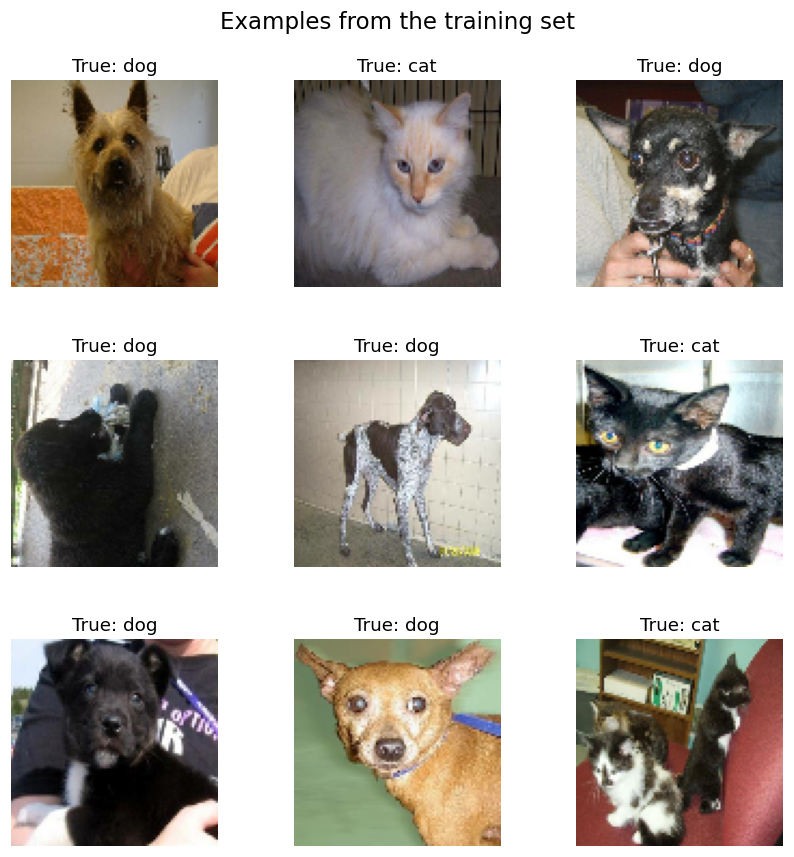

In [5]:
def load_image(path, label):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3,
                              expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    return tf.cast(image, tf.float32), tf.cast(label, tf.float32)


def make_dataset(items, training=False):
    paths = [item['path'] for item in items]
    labels = np.array([item['label'] for item in items], dtype=np.float32)[:, None]
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        dataset = dataset.shuffle(len(items), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.map(load_image, num_parallel_calls=2)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    options.threading.max_intra_op_parallelism = 1
    options.experimental_deterministic = True
    return dataset.with_options(options).batch(BATCH_SIZE).prefetch(1)


if DATA_READY:
    train_ds = make_dataset(train_records, training=True)
    train_eval_ds = make_dataset(train_records)
    val_ds = make_dataset(val_records)
    test_ds = make_dataset(test_records)
    images, labels = next(iter(train_ds))
    assert tuple(images.shape[1:]) == (*IMAGE_SIZE, 3)
    assert bool(tf.reduce_all(tf.math.is_finite(images)))
    print('Image batch shape:', images.shape)
    print('Label batch shape:', labels.shape)
    fig, axes = plt.subplots(3, 3, figsize=(8, 8))
    for index, ax in enumerate(axes.flat):
        ax.axis('off')
        if index < len(images):
            ax.imshow(np.clip(images[index].numpy() / 255.0, 0, 1))
            ax.set_title('True: ' + CLASS_NAMES[int(labels[index, 0])])
    fig.suptitle('Examples from the training set', fontsize=15)
    fig.subplots_adjust(left=0.03, right=0.97, bottom=0.03, top=0.90,
                        hspace=0.35, wspace=0.08)
    plt.show()
else:
    print('PENDING — image batches and preview require the Canvas dataset.')


## 4. Create the CNN with Keras

Three convolution/pooling blocks with 16, 32, and 64 filters learn image features,
followed by a dense layer
and one sigmoid output. The output is the model's score for **dog**; a score
greater than 0.5 selects dog, otherwise cat. Binary cross-entropy matches this two-class
output. Random flips, small rotations, and dropout operate during training only.

The model is trained from scratch. The MNIST `sample_weight.pkl` file is not
compatible with this CNN and is not used.


In [6]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

cnn = keras.Sequential([
    keras.Input(shape=(*IMAGE_SIZE, 3), name='rgb_image'),
    layers.Rescaling(1.0 / 255.0, name='normalize'),
    layers.RandomFlip('horizontal', seed=SEED, name='random_flip'),
    layers.RandomRotation(0.05, seed=SEED + 1, name='random_rotation'),
    layers.Conv2D(16, 3, activation='relu', padding='same', name='conv_1'),
    layers.MaxPooling2D(name='pool_1'),
    layers.Conv2D(32, 3, activation='relu', padding='same', name='conv_2'),
    layers.MaxPooling2D(name='pool_2'),
    layers.Conv2D(64, 3, activation='relu', padding='same', name='conv_3'),
    layers.MaxPooling2D(name='pool_3'),
    layers.Flatten(name='flatten'),
    layers.Dense(64, activation='relu', name='dense_features'),
    layers.Dropout(0.5, seed=SEED + 2, name='dropout'),
    layers.Dense(1, activation='sigmoid', name='dog_probability'),
], name='cat_dog_cnn')

cnn.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
            loss='binary_crossentropy',
            metrics=[keras.metrics.BinaryAccuracy(name='accuracy')])
cnn.summary()
assert cnn.output_shape == (None, 1)
print('CNN is compiled and ready to train.')


Model: "cat_dog_cnn"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalize (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 96, 96, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 96, 96, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 48, 48, 16) 

## 5. Train for exactly 10 epochs

The training set updates the weights. The validation set is evaluated after each
epoch without updating weights. Every training batch is used in each epoch; there
is no early-stopping callback or shortened `steps_per_epoch` setting. The test set
is reserved for the final evaluation below. The callbacks record each epoch and
save the latest weights. Evaluation uses the final, tenth-epoch model.


In [7]:
TRAINING_COMPLETED = False
if DATA_READY:
    initial_weights = [weight.copy() for weight in cnn.get_weights()]
    callbacks = [
        keras.callbacks.CSVLogger(str(RUN_DIR / 'training_history.csv')),
        keras.callbacks.ModelCheckpoint(str(RUN_DIR / 'last_epoch.weights.h5'),
                                        save_weights_only=True, save_best_only=False),
    ]
    start = time.perf_counter()
    history = cnn.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                      shuffle=False, verbose=2, callbacks=callbacks)
    elapsed = time.perf_counter() - start
    assert len(history.epoch) == 10, 'Training did not complete all 10 epochs.'
    assert all(np.all(np.isfinite(values)) for values in history.history.values())
    assert any(not np.array_equal(before, after)
               for before, after in zip(initial_weights, cnn.get_weights()))
    cnn.save(RUN_DIR / 'cat_dog_cnn.keras')
    (RUN_DIR / 'history.json').write_text(json.dumps(history.history, indent=2))
    TRAINING_COMPLETED = True
    print(f'Completed {len(history.epoch)} epochs in {elapsed / 60:.2f} minutes.')
else:
    print('PENDING — no CNN training has been performed; Canvas images are missing.')


Epoch 1/10
500/500 - 37s - 73ms/step - accuracy: 0.6336 - loss: 0.6332 - val_accuracy: 0.7165 - val_loss: 0.5531
Epoch 2/10
500/500 - 47s - 95ms/step - accuracy: 0.7353 - loss: 0.5389 - val_accuracy: 0.7688 - val_loss: 0.4866
Epoch 3/10
500/500 - 33s - 66ms/step - accuracy: 0.7629 - loss: 0.4956 - val_accuracy: 0.7953 - val_loss: 0.4435
Epoch 4/10
500/500 - 33s - 67ms/step - accuracy: 0.7870 - loss: 0.4594 - val_accuracy: 0.8114 - val_loss: 0.4157
Epoch 5/10
500/500 - 37s - 75ms/step - accuracy: 0.8014 - loss: 0.4362 - val_accuracy: 0.8121 - val_loss: 0.4087
Epoch 6/10
500/500 - 38s - 75ms/step - accuracy: 0.8159 - loss: 0.4141 - val_accuracy: 0.8116 - val_loss: 0.4005
Epoch 7/10
500/500 - 31s - 63ms/step - accuracy: 0.8253 - loss: 0.3952 - val_accuracy: 0.8226 - val_loss: 0.4132
Epoch 8/10
500/500 - 35s - 69ms/step - accuracy: 0.8333 - loss: 0.3760 - val_accuracy: 0.8346 - val_loss: 0.3624
Epoch 9/10
500/500 - 37s - 74ms/step - accuracy: 0.8451 - loss: 0.3578 - val_accuracy: 0.8336 - 

Epoch   Train loss    Train acc     Val loss      Val acc
    1       0.6332      63.36%        0.5531      71.65%
    2       0.5389      73.53%        0.4866      76.88%
    3       0.4956      76.29%        0.4435      79.53%
    4       0.4594      78.70%        0.4157      81.14%
    5       0.4362      80.14%        0.4087      81.21%
    6       0.4141      81.59%        0.4005      81.16%
    7       0.3952      82.53%        0.4132      82.26%
    8       0.3760      83.33%        0.3624      83.46%
    9       0.3578      84.51%        0.3601      83.36%
   10       0.3539      84.69%        0.3412      84.69%


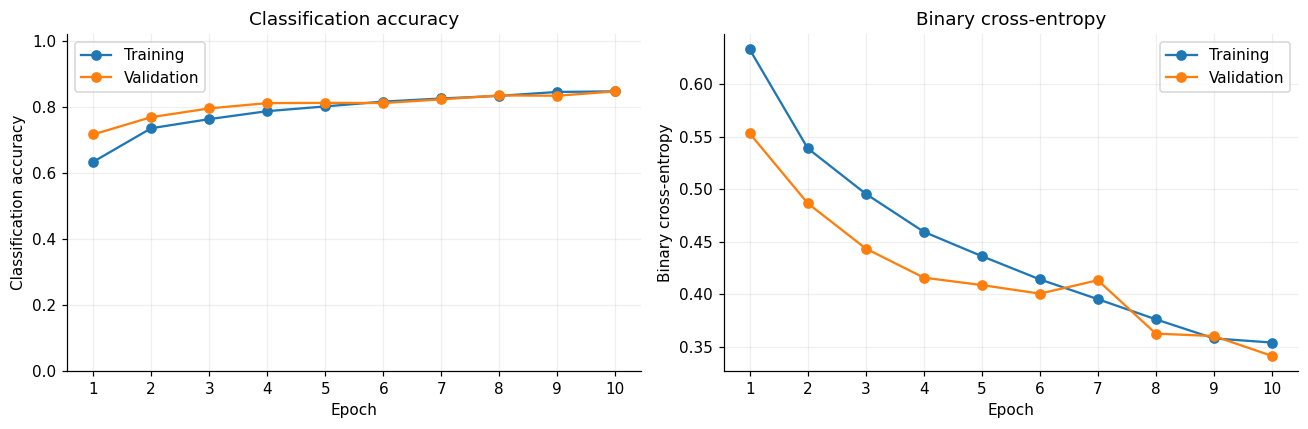

In [8]:
if TRAINING_COMPLETED:
    epoch_numbers = np.arange(1, EPOCHS + 1)
    print(f"{'Epoch':>5}{'Train loss':>13}{'Train acc':>13}{'Val loss':>13}{'Val acc':>13}")
    for i in range(EPOCHS):
        print(f"{i + 1:>5}{history.history['loss'][i]:>13.4f}"
              f"{history.history['accuracy'][i]:>12.2%}"
              f"{history.history['val_loss'][i]:>14.4f}"
              f"{history.history['val_accuracy'][i]:>12.2%}")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric, title in zip(axes, ['accuracy', 'loss'],
                                ['Classification accuracy', 'Binary cross-entropy']):
        ax.plot(epoch_numbers, history.history[metric], marker='o', label='Training')
        ax.plot(epoch_numbers, history.history['val_' + metric], marker='o',
                label='Validation')
        ax.set(xlabel='Epoch', ylabel=title, title=title, xticks=epoch_numbers)
        ax.grid(alpha=0.2)
        ax.legend()
    axes[0].set_ylim(0, 1.02)
    plt.tight_layout()
    plt.show()
else:
    print('PENDING — learning curves appear after the 10-epoch training run.')


## 6. Evaluate training, validation, and test performance

All three evaluations use inference mode, with random augmentation and dropout
disabled. Consequently, evaluated training accuracy can differ from the training
accuracy logged while fitting. The final test accuracy measures performance on
images withheld from weight updates and validation monitoring.


In [9]:
EVALUATION_COMPLETED = False
if TRAINING_COMPLETED:
    evaluation = {}
    for name, dataset in [('Training', train_eval_ds), ('Validation', val_ds),
                          ('Test', test_ds)]:
        evaluation[name] = cnn.evaluate(dataset, return_dict=True, verbose=0)
    print(f"{'Dataset':<14}{'Images':>9}{'Loss':>12}{'Accuracy':>13}")
    for name, result in evaluation.items():
        assert np.isfinite(result['loss']) and 0 <= result['accuracy'] <= 1
        print(f"{name:<14}{len(split_records[name]):>9}{result['loss']:>12.4f}"
              f"{result['accuracy']:>12.2%}")
    test_labels = np.array([item['label'] for item in test_records])
    majority_baseline = max(np.bincount(test_labels, minlength=2)) / len(test_labels)
    print(f'Always-predict-the-majority-class test baseline: {majority_baseline:.2%}')
    gap = evaluation['Training']['accuracy'] - evaluation['Validation']['accuracy']
    print(f'Training minus validation accuracy: {gap * 100:.2f} percentage points.')
    (RUN_DIR / 'evaluation.json').write_text(json.dumps(evaluation, indent=2))
    EVALUATION_COMPLETED = True
else:
    print('PENDING — training, validation, and test metrics have not been measured.')


Dataset          Images        Loss     Accuracy
Training          15988      0.2957      87.29%
Validation         3997      0.3412      84.69%
Test               4999      0.3369      85.18%
Always-predict-the-majority-class test baseline: 50.01%
Training minus validation accuracy: 2.60 percentage points.


## 7. Compare predicted labels with the true labels

Test data are not shuffled, so the prediction vector matches the recorded labels.
The confusion matrix shows counts, with true labels on rows and predicted labels
on columns. The displayed examples use a fixed random sample of test images;
correct and incorrect predictions are both allowed to appear.


Prediction-based test accuracy: 85.18%
Correct test predictions: 4,258 / 4,999
Confusion matrix: rows = true labels, columns = predicted labels
[[2002  497]
 [ 244 2256]]


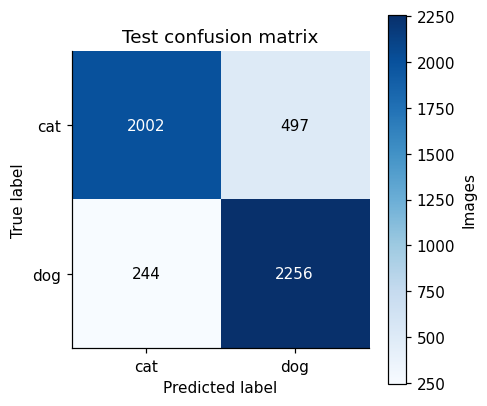

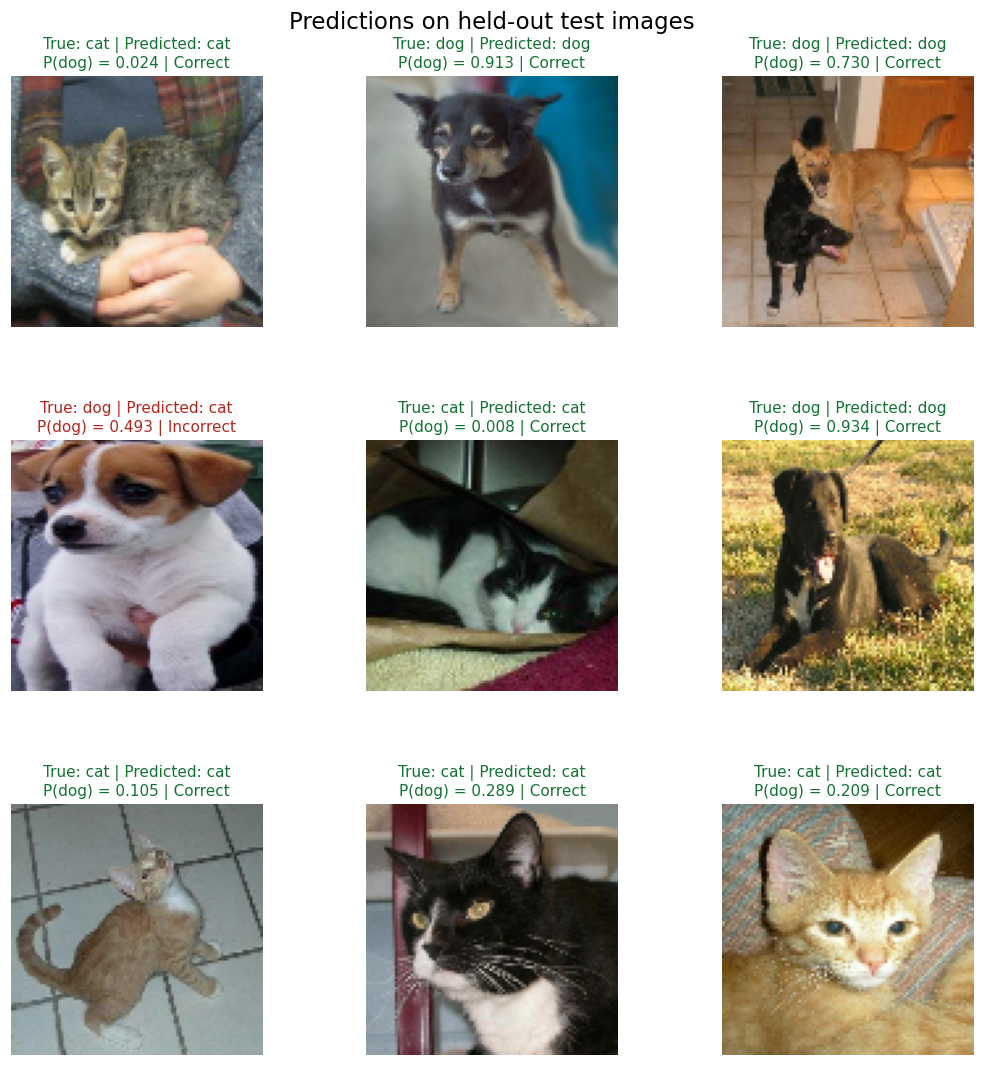

In [10]:
PREDICTIONS_COMPLETED = False
if EVALUATION_COMPLETED:
    dog_scores = cnn.predict(test_ds, verbose=0).reshape(-1)
    predicted_labels = (dog_scores > 0.5).astype(int)
    assert len(dog_scores) == len(test_labels)
    assert np.all(np.isfinite(dog_scores))
    direct_accuracy = float(np.mean(predicted_labels == test_labels))
    assert np.isclose(direct_accuracy, evaluation['Test']['accuracy'], atol=1e-6)
    matrix = tf.math.confusion_matrix(test_labels, predicted_labels, num_classes=2).numpy()
    assert int(matrix.sum()) == len(test_labels)
    print(f'Prediction-based test accuracy: {direct_accuracy:.2%}')
    print(f'Correct test predictions: {int(np.count_nonzero(predicted_labels == test_labels)):,}'
          f' / {len(test_labels):,}')
    np.savez_compressed(RUN_DIR / 'test_predictions.npz', labels=test_labels,
                        dog_scores=dog_scores, predicted_labels=predicted_labels)
    print('Confusion matrix: rows = true labels, columns = predicted labels')
    print(matrix)

    fig, ax = plt.subplots(figsize=(4.5, 4))
    heatmap = ax.imshow(matrix, cmap='Blues')
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=CLASS_NAMES,
           yticklabels=CLASS_NAMES, xlabel='Predicted label', ylabel='True label',
           title='Test confusion matrix')
    for row in range(2):
        for column in range(2):
            ax.text(column, row, str(matrix[row, column]), ha='center', va='center',
                    color='white' if matrix[row, column] > matrix.max() / 2 else 'black')
    fig.colorbar(heatmap, ax=ax, label='Images')
    plt.tight_layout()
    plt.show()

    sample_indices = np.random.default_rng(SEED).choice(
        len(test_records), size=min(9, len(test_records)), replace=False)
    fig, axes = plt.subplots(3, 3, figsize=(10, 10))
    for ax in axes.flat:
        ax.axis('off')
    for ax, index in zip(axes.flat, sample_indices):
        record = test_records[index]
        image, _ = load_image(record['path'], record['label'])
        actual, prediction = int(test_labels[index]), int(predicted_labels[index])
        result = 'Correct' if actual == prediction else 'Incorrect'
        ax.imshow(np.clip(image.numpy() / 255.0, 0, 1))
        ax.set_title(f'True: {CLASS_NAMES[actual]} | Predicted: {CLASS_NAMES[prediction]}\n'
                     f'P(dog) = {dog_scores[index]:.3f} | {result}',
                     color='#137333' if actual == prediction else '#b3261e', fontsize=10)
    fig.suptitle('Predictions on held-out test images', fontsize=15)
    fig.subplots_adjust(left=0.03, right=0.97, bottom=0.03, top=0.92,
                        hspace=0.45, wspace=0.10)
    plt.show()
    PREDICTIONS_COMPLETED = True
else:
    print('PENDING — prediction examples need a trained CNN and the labeled test set.')


## 8. Result and interpretation

Use the saved outputs above to judge performance. A widening gap between training
and validation accuracy suggests overfitting. Compare test accuracy with the
majority-class baseline and inspect both the confusion matrix and prediction
examples; completing training does not by itself establish good classification.
The split seed is fixed, but hardware and TensorFlow versions can still affect
the exact numerical results.


In [11]:
if TRAINING_COMPLETED and EVALUATION_COMPLETED and PREDICTIONS_COMPLETED:
    assert len(history.epoch) == 10
    print('COMPLETE — 10 epochs trained and validation/test results saved.')
    print(f"Validation accuracy: {evaluation['Validation']['accuracy']:.2%}")
    print(f"Test accuracy:       {evaluation['Test']['accuracy']:.2%}")
    print('Saved outputs include learning curves, confusion matrix, and prediction examples.')
    print(f"Training accuracy:   {evaluation['Training']['accuracy']:.2%}")
    print(f'Test accuracy above the majority-class baseline: '
          f"{100 * (evaluation['Test']['accuracy'] - majority_baseline):.2f} percentage points.")
    print('PASS: all 10 epochs completed, weights changed, results are finite, and')
    print('prediction-based accuracy agrees with the Keras test evaluation.')
else:
    print('PENDING — this CNN notebook is not yet a completed training submission.')
    print('Provide the Canvas dataset, set DATA_DIR, choose Run All, and save the outputs.')
    print('Metrics and prediction figures will appear after that run.')


COMPLETE — 10 epochs trained and validation/test results saved.
Validation accuracy: 84.69%
Test accuracy:       85.18%
Saved outputs include learning curves, confusion matrix, and prediction examples.
Training accuracy:   87.29%
Test accuracy above the majority-class baseline: 35.17 percentage points.
PASS: all 10 epochs completed, weights changed, results are finite, and
prediction-based accuracy agrees with the Keras test evaluation.


## References

- [TensorFlow: Image classification](https://www.tensorflow.org/tutorials/images/classification)
- [TensorFlow: Load and preprocess images](https://www.tensorflow.org/tutorials/load_data/images)
- [TensorFlow: Data augmentation](https://www.tensorflow.org/tutorials/images/data_augmentation)
- [Keras: Model training APIs](https://keras.io/api/models/model_training_apis/)

Dataset source: the course cat-and-dog images uploaded as two ZIP parts of
`data_from_kaggle.zip`. The recorded metrics are generated by the executed cells.
